In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import torch

In [2]:
def f(x,y):
    return np.exp(-(x**2+y**2)/(0.25**2))

In [3]:
def func(x, y, c, l):
    return np.sum((c**2)[:,None]*np.cos(l[:,0][:,None]*x[None] + l[:,1][:,None]*y[None]), axis = 0)

In [4]:
N = 256

In [5]:
def block_diag(fill_vals):
    # Helper function to create block-diagonal skew-symmetric matrices
    blocks = []
    for i in range(len(fill_vals)):
        block = torch.zeros((2,2))
        
        block[0,1] = fill_vals[i]
        block[1,0] = -block[0,1]
        blocks.append(block)
    return torch.block_diag(*blocks)

In [ ]:
super_diags = torch.tensor(np.random.normal(0, 3, (N//2, 2)).astype(np.float32))
sA = block_diag(super_diags[:,0])
sB = block_diag(super_diags[:,1])

eigenvals = torch.cat((super_diags, -super_diags), dim=0)

u = (torch.rand((N, N)).to(torch.float32) - 0.5)*2 # random
Gr = u - u.T # skew symmetric
R = torch.matrix_exp(Gr) # orthogonal, s = 1

p0 = R.T@torch.tensor(np.ones(len(R)).astype(np.float32))
c = torch.ones(N)

(-10.957193851470947,
 10.957193851470947,
 -11.232962799072265,
 11.232962799072265)

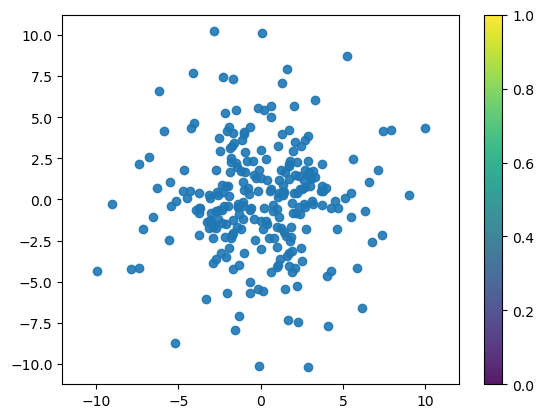

In [7]:
plt.scatter(eigenvals[:,0].detach().numpy(), eigenvals[:,1].detach().numpy(), alpha=0.9)
plt.colorbar()
plt.axis("equal")

In [8]:
torch.save(sA, "sigma_A.pt")
torch.save(sB, "sigma_B.pt")
torch.save(Gr, "Gr.pt")
torch.save(p0, "p0.pt")

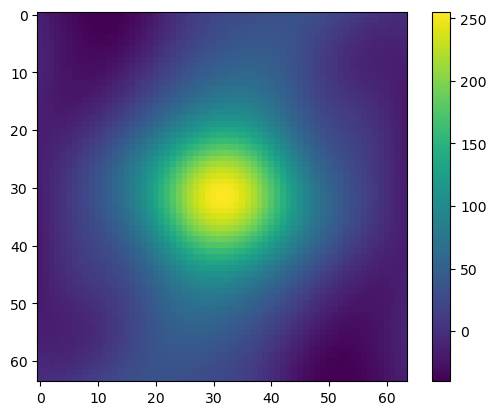

In [9]:
x = np.linspace(-1, 1, 64)*1
y = np.linspace(-1, 1, 64)*1
X, Y = np.meshgrid(x, y)
r = np.stack([X.ravel(), Y.ravel()], axis=1)
d = func(r[:,0], r[:,1], c.numpy(), eigenvals.numpy())

plt.imshow(d.reshape(X.shape))
plt.colorbar()